# Deep reinforcement learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/deep-rl/deep-rl-notebook.ipynb)

Companion notebook for the *Deep reinforcement learning* slides. Each idea is written first by hand
with NumPy and then checked with an independent computation that should give the same answer.

**Data:** no data set; the agent moves in the deck's corridor: position $s$ from 0 to 1, each move shifts it by 0.1,
the left end pays +0.5 and the right end +1, $\gamma = 0.8$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import softmax

RANDOM_STATE = 42
GAMMA = 0.8
ALPHA = 0.5
BATCH = 32
STEPS = 3000
COPY_EVERY = 50
rng = np.random.default_rng(RANDOM_STATE)

POSITIONS = np.round(np.arange(1, 10) / 10, 1)  # non-terminal positions 0.1 ... 0.9
LEFT, RIGHT = 0, 1


def step(s, a):
    """The environment: return (reward, next position, done)."""
    s_next = round(s + (0.1 if a == RIGHT else -0.1), 1)
    if s_next <= 0:
        return 0.5, s_next, True
    if s_next >= 1:
        return 1.0, s_next, True
    return 0.0, s_next, False

## 1. A linear Q-function

$Q(s, a; \boldsymbol\theta) = \boldsymbol\theta_a^\top \boldsymbol\phi(s)$, learned with
$\boldsymbol\theta_a \leftarrow \boldsymbol\theta_a + \alpha\,\delta\,\boldsymbol\phi(s)$.
A table is the special case where $\boldsymbol\phi(s)$ marks one state, so both should learn the same numbers.

In [2]:
def one_hot(s):
    return np.eye(len(POSITIONS))[int(round(s * 10)) - 1]


theta = np.zeros((2, len(POSITIONS)))  # one weight vector per action
table = np.zeros((len(POSITIONS), 2))  # Topic 21's Q-table
for _ in range(500):
    s, a = rng.choice(POSITIONS), rng.integers(2)
    r, s_next, done = step(s, a)
    i = int(round(s * 10)) - 1

    delta = (r if done else r + GAMMA * (theta @ one_hot(s_next)).max()) - theta[a] @ one_hot(s)
    theta[a] += 0.1 * delta * one_hot(s)

    table_delta = (r if done else r + GAMMA * table[i + (1 if a == RIGHT else -1)].max()) - table[i, a]
    table[i, a] += 0.1 * table_delta

print("same result:", np.allclose(theta.T, table))

same result: True


## 2. The DQN loss and its gradient

A small network (one hidden layer of `tanh` units, one output per action) gives $Q(s, a; \boldsymbol\theta)$.
The loss is $L(\boldsymbol\theta) = \frac{1}{B}\sum_i \big(y_i - Q(s_i, a_i; \boldsymbol\theta)\big)^2$ with the targets
$y_i = r_i + \gamma \max_{a'} Q(s'_i, a'; \boldsymbol\theta^-)$ held fixed. Backpropagation by hand should match
a finite-difference gradient.

In [3]:
def q_network(params, s):
    W1, b1, W2, b2 = params
    hidden = np.tanh(np.outer(s, W1) + b1)
    return hidden @ W2 + b2, hidden


params = [rng.normal(size=8), rng.normal(size=8), rng.normal(size=(8, 2)), np.zeros(2)]
frozen = [p.copy() for p in params]  # the target network theta^-

batch = [(s, a, *step(s, a)) for s, a in zip(rng.choice(POSITIONS, BATCH), rng.integers(2, size=BATCH))]
s_b, a_b, r_b, next_b, done_b = map(np.array, zip(*batch))
y = r_b + GAMMA * q_network(frozen, next_b)[0].max(axis=1) * (1 - done_b)


def loss(params):
    q, _ = q_network(params, s_b)
    return np.mean((y - q[np.arange(BATCH), a_b]) ** 2)

In [4]:
W1, b1, W2, b2 = params
q, hidden = q_network(params, s_b)
d_q = np.zeros_like(q)
d_q[np.arange(BATCH), a_b] = 2 * (q[np.arange(BATCH), a_b] - y) / BATCH
d_hidden = d_q @ W2.T * (1 - hidden ** 2)
gradient = [d_hidden.T @ s_b, d_hidden.sum(axis=0), hidden.T @ d_q, d_q.sum(axis=0)]

numeric = []
for p in params:
    g = np.zeros_like(p)
    for i in np.ndindex(p.shape):
        p[i] += 1e-6
        up = loss(params)
        p[i] -= 2e-6
        g[i] = (up - loss(params)) / 2e-6
        p[i] += 1e-6
    numeric.append(g)

print(f"loss {loss(params):.3f} | same result:", all(np.allclose(g, n, atol=1e-6) for g, n in zip(gradient, numeric)))

loss 0.117 | same result: True


## 3. Training with replay and a target network

As in the deck, a linear $Q$ on 8 bumps $\phi_k(s) = e^{-(s - c_k)^2 / (2 \cdot 0.1^2)}$ learns from random moves.
Each step is stored in a replay buffer, each update uses a random mini-batch, and the targets come from a
frozen copy $\boldsymbol\theta^-$ that is refreshed every `COPY_EVERY` steps.

In [5]:
CENTERS = np.linspace(0, 1, 8)


def bumps(s):
    return np.exp(-(np.atleast_1d(s)[:, None] - CENTERS) ** 2 / (2 * 0.1 ** 2))


theta = np.zeros((2, len(CENTERS)))
buffer = []
s = rng.choice(POSITIONS)
for t in range(STEPS):
    if t % COPY_EVERY == 0:
        theta_frozen = theta.copy()
    a = rng.integers(2)
    r, s_next, done = step(s, a)
    buffer.append((s, a, r, s_next, done))
    s = rng.choice(POSITIONS) if done else s_next

    s_b, a_b, r_b, next_b, done_b = map(np.array, zip(*[buffer[i] for i in rng.integers(len(buffer), size=BATCH)]))
    y = r_b + GAMMA * (bumps(next_b) @ theta_frozen.T).max(axis=1) * (1 - done_b)
    delta = y - (bumps(s_b) @ theta.T)[np.arange(BATCH), a_b]
    np.add.at(theta, a_b, ALPHA / BATCH * delta[:, None] * bumps(s_b))

The exact $Q^*$ comes from value iteration on the nine positions (Topic 20). The network's values are
approximate, so we compare them with a tolerance and check that its greedy action is the optimal one everywhere.

same values: True
same policy: True


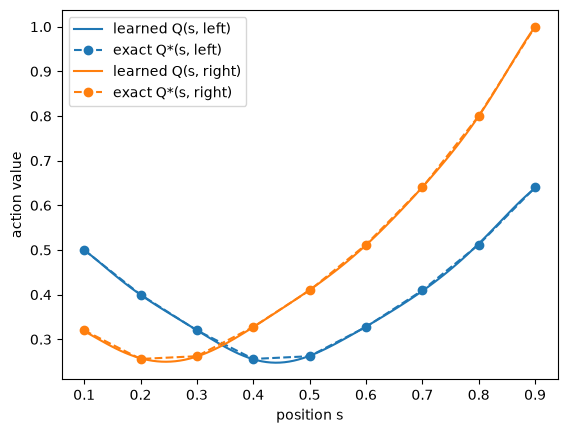

In [6]:
Q_star = np.zeros((len(POSITIONS), 2))
for _ in range(100):
    for i, s in enumerate(POSITIONS):
        for a in (LEFT, RIGHT):
            r, s_next, done = step(s, a)
            Q_star[i, a] = r if done else r + GAMMA * Q_star[i + (1 if a == RIGHT else -1)].max()

Q_learned = bumps(POSITIONS) @ theta.T
print("same values:", np.allclose(Q_learned, Q_star, atol=0.05))
print("same policy:", np.array_equal(Q_learned.argmax(axis=1), Q_star.argmax(axis=1)))

grid = np.linspace(0.1, 0.9, 100)
for a, name in [(LEFT, "left"), (RIGHT, "right")]:
    line, = plt.plot(grid, bumps(grid) @ theta[a], label=f"learned Q(s, {name})")
    plt.plot(POSITIONS, Q_star[:, a], "o--", color=line.get_color(), label=f"exact Q*(s, {name})")
plt.xlabel("position s")
plt.ylabel("action value")
plt.legend()
plt.show()

## 4. A policy network

A softmax turns preferences into probabilities, $\pi(a \mid s) = e^{h_a} / \sum_b e^{h_b}$. REINFORCE moves the
preferences along $\alpha\, G\, \nabla \log \pi(a)$; when the parameters are the preferences this is the deck's rule
$h_a \mathrel{+}= \alpha G (1 - \pi(a))$, $h_b \mathrel{-}= \alpha G\, \pi(b)$, which should match a numerical gradient.

In [7]:
h = np.zeros(3)
chosen, G, alpha = 0, 1.0, 0.5

pi = np.exp(h) / np.exp(h).sum()
h_rule = h - alpha * G * pi
h_rule[chosen] += alpha * G
print("softmax same result:", np.allclose(pi, softmax(h)))


def log_pi(h):
    return np.log(softmax(h)[chosen])


grad_log_pi = np.array([(log_pi(h + 1e-6 * e) - log_pi(h - 1e-6 * e)) / 2e-6 for e in np.eye(3)])
print("new probabilities:", softmax(h_rule).round(2))
print("same result:", np.allclose(h_rule, h + alpha * G * grad_log_pi))

softmax same result: True
new probabilities: [0.45 0.27 0.27]
same result: True


## Exercises

1. In section 3, set `COPY_EVERY = 1` (no frozen copy) and `BATCH = 1` (no replay). Do the checks still pass?
2. Use 3 bumps instead of 8 in section 3. Where does the learned policy go wrong, and why?
3. Apply the rule of section 4 for 50 pulls of three arms that win with chances 0.2, 0.5 and 0.8. Which arm ends most likely?